BÀI 1

--- HỆ SỐ TƯƠNG QUAN VỚI TARGET ---
bmi    0.586450
bp     0.441482
s5     0.565883
Name: target, dtype: float64


--- THỐNG KÊ OUTLIER (IQR METHOD) ---
Cột bmi: Có 3 điểm outlier (0.68%)
Cột bp: Có 0 điểm outlier (0.00%)
Cột s5: Có 4 điểm outlier (0.90%)


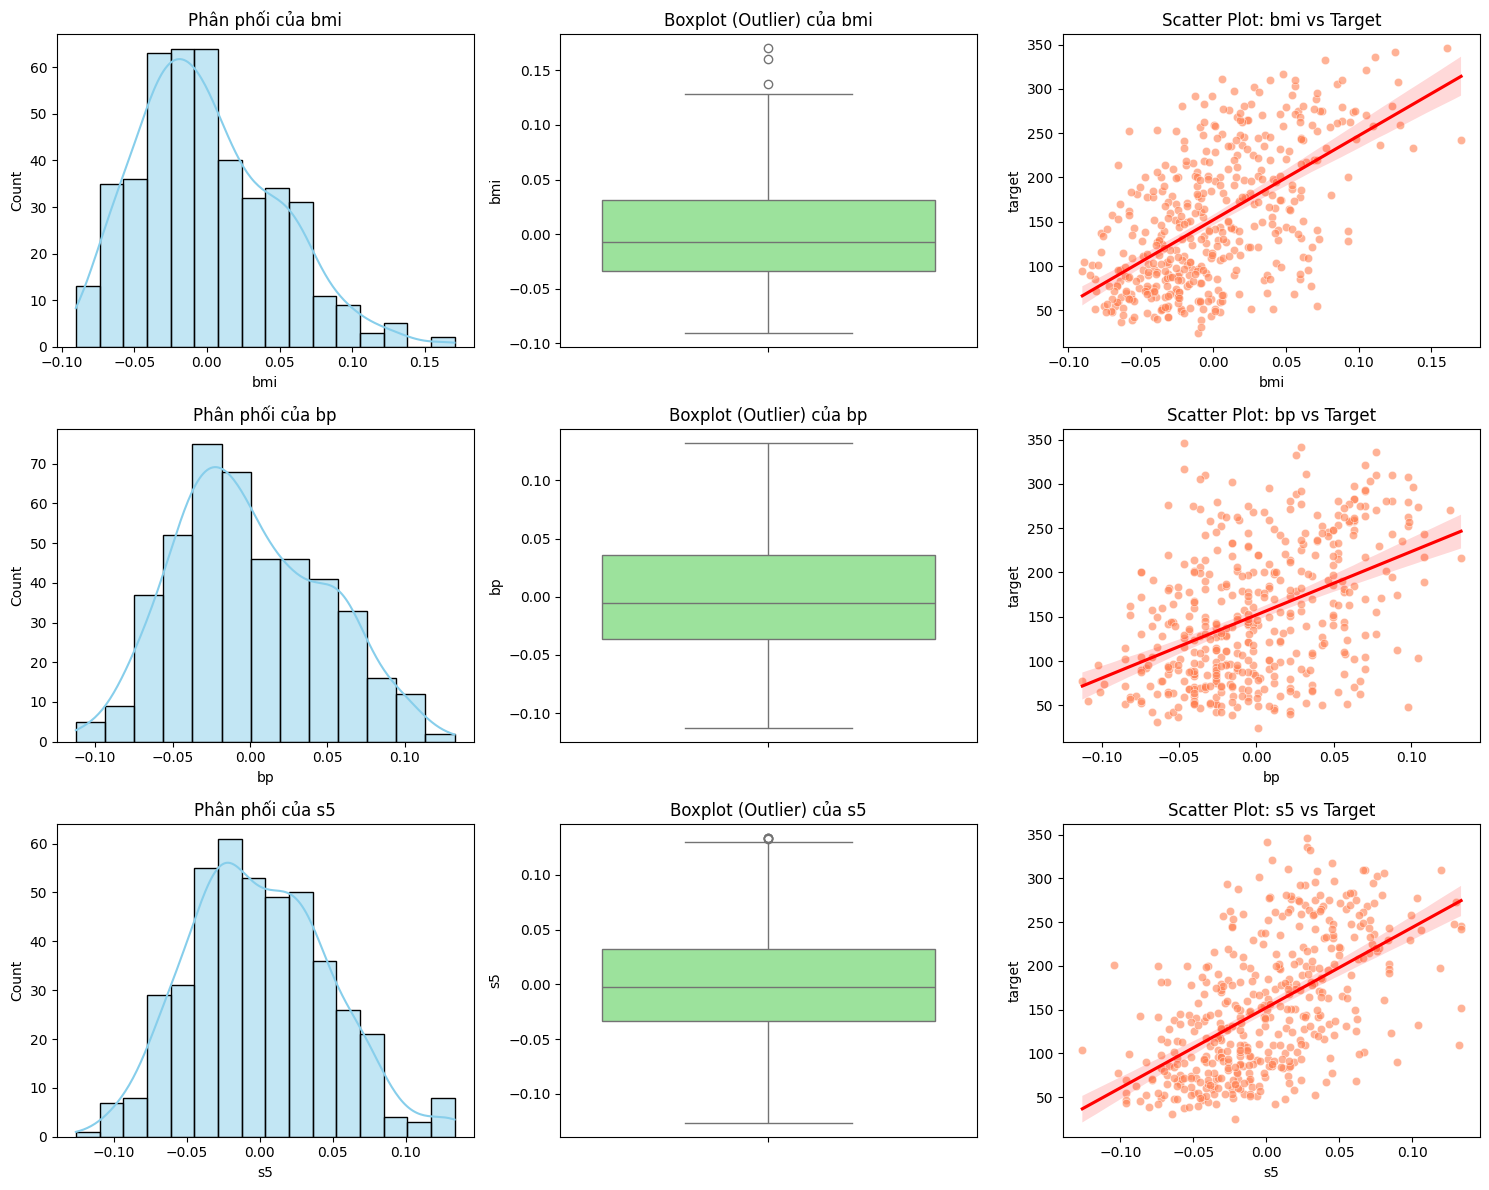

In [8]:
import numpy as np

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.datasets import load_diabetes

# 1. Nạp dữ liệu Diabetes
diabetes = load_diabetes()
df = pd.DataFrame(diabetes.data, columns=diabetes.feature_names)
df['target'] = diabetes.target

# 3 features đã chọn
selected_features = ['bmi', 'bp', 's5']

# 2. Tính hệ số tương quan với target
print("--- HỆ SỐ TƯƠNG QUAN VỚI TARGET ---")
corr = df[selected_features + ['target']].corr() # tính hệ số tương quan
print(corr['target'].drop('target'))

print("\n" + "=" * 40 + "\n")

# 3. Thống kê Outlier theo IQR
print("--- THỐNG KÊ OUTLIER (IQR METHOD) ---")
for col in selected_features:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    outliers = df[(df[col] < (Q1 - 1.5 * IQR)) | (df[col] > (Q3 + 1.5 * IQR))]
    print(f"Cột {col}: Có {len(outliers)} điểm outlier ({len(outliers) / len(df) * 100:.2f}%)")

# 4. Vẽ biểu đồ 3x3 (Phân phối, Outlier, Scatter plot)
fig, axes = plt.subplots(3, 3, figsize=(15, 12))

for i, col in enumerate(selected_features):
    # Biểu đồ Phân phối
    sns.histplot(df[col], kde=True, ax=axes[i, 0], color='skyblue')
    axes[i, 0].set_title(f'Phân phối của {col}')

    # Biểu đồ Boxplot (Outlier)
    sns.boxplot(y=df[col], ax=axes[i, 1], color='lightgreen')
    axes[i, 1].set_title(f'Boxplot (Outlier) của {col}')

    # Biểu đồ Scatter Plot với Target
    sns.scatterplot(x=df[col], y=df['target'], ax=axes[i, 2], alpha=0.6, color='coral')
    sns.regplot(x=df[col], y=df['target'], ax=axes[i, 2], scatter=False, color='red')
    axes[i, 2].set_title(f'Scatter Plot: {col} vs Target')

plt.tight_layout()
plt.show()

BÀI 2

In [9]:
import numpy as np
import pandas as pd
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Nạp dữ liệu Diabetes
diabetes = load_diabetes()
df = pd.DataFrame(diabetes.data, columns=diabetes.feature_names)
df['target'] = diabetes.target

# 2. Xác định Top 5 features theo độ tương quan tuyệt đối với target
top5_features = df.corr()['target'].abs().drop('target').nlargest(5).index.tolist()

# 3. Độ nghiệp 4 tập features theo yêu cầu đề bài
feature_sets = {
    "1. bmi": ['bmi'],
    "2. bmi + bp": ['bmi', 'bp'],
    f"3. Top 5 Tương quan ({', '.join(top5_features)})": top5_features,
    "4. Toàn bộ 10 features": diabetes.feature_names
}

results = []

# 4. Vòng lặp huấn luyện và đánh giá trên từng tập feature
for set_name, features in feature_sets.items():
    X = df[features]
    y = df['target']

    # Chia tập dữ liệu ngẫu nhiên (80% Train / 20% Test)
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

    # Chuẩn hóa dữ liệu
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)

    # Huấn luyện mô hình
    model = LinearRegression()
    model.fit(X_train_scaled, y_train)

    # Dự báo
    y_pred = model.predict(X_test_scaled)

    # Tính toán chỉ số MAE, RMSE, R2
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))  # RMSE = Căn bậc hai của MSE
    r2 = r2_score(y_test, y_pred)

    results.append({
        "Bộ Features": set_name,
        "Số lượng Features": len(features),
        "MAE": round(mae, 2), # sai số tuyệt đối trung bình
        "RMSE": round(rmse, 2), # căn bậc 2 của sai số tuyển đối trung bình
        "R² Score": round(r2, 4) # hệ số trung bình
    })

# 5. In bảng so sánh kết quả
results_df = pd.DataFrame(results)
print("=== BẢNG SO SÁNH KẾT QUẢ HUẤN LUYỆN BÀI 2 ===")
print(results_df.to_string(index=False))

=== BẢNG SO SÁNH KẾT QUẢ HUẤN LUYỆN BÀI 2 ===
                              Bộ Features  Số lượng Features   MAE  RMSE  R² Score
                                   1. bmi                  1 52.26 63.73    0.2334
                              2. bmi + bp                  2 50.04 61.16    0.2940
3. Top 5 Tương quan (bmi, s5, bp, s4, s3)                  5 43.93 54.19    0.4458
                   4. Toàn bộ 10 features                 10 42.79 53.85    0.4526


BÀI 3

In [10]:
import numpy as np
import pandas as pd
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Import 5 thuật toán theo đề bài
from sklearn.linear_model import LinearRegression, Ridge #
from sklearn.tree import DecisionTreeRegressor
from sklearn.svm import SVR
from sklearn.ensemble import GradientBoostingRegressor

# 1. Nạp dữ liệu Diabetes (dùng toàn bộ 10 features)
diabetes = load_diabetes()
X = pd.DataFrame(diabetes.data, columns=diabetes.feature_names)
y = diabetes.target

# 2. Chia tập Train / Test (80/20)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Chuẩn hóa dữ liệu
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 4. Khai báo danh sách các mô hình
models = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(alpha=1.0),
    "Decision Tree Regression": DecisionTreeRegressor(random_state=42),
    "Support Vector Regression (SVR)": SVR(kernel='rbf'),
    "Gradient Boosting Regression": GradientBoostingRegressor(random_state=42)
}

# 5. Huấn luyện và đánh giá từng mô hình
results = []

for name, model in models.items():
    # Huấn luyện mô hình
    model.fit(X_train_scaled, y_train)

    # Dự báo trên tập test
    y_pred = model.predict(X_test_scaled)

    # Tính các chỉ số
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)

    results.append({
        "Thuật toán": name,
        "MAE": round(mae, 2),
        "RMSE": round(rmse, 2),
        "R² Score": round(r2, 4)
    })

# 6. Hiển thị bảng so sánh
results_df = pd.DataFrame(results).sort_values(by="R² Score", ascending=False)
print("=== BẢNG SO SÁNH CÁC THUẬT TOÁN (BÀI 3) ===")
print(results_df.to_string(index=False))

=== BẢNG SO SÁNH CÁC THUẬT TOÁN (BÀI 3) ===
                     Thuật toán   MAE  RMSE  R² Score
               Ridge Regression 42.81 53.78    0.4541
   Gradient Boosting Regression 44.59 53.83    0.4530
              Linear Regression 42.79 53.85    0.4526
Support Vector Regression (SVR) 56.03 65.82    0.1822
       Decision Tree Regression 53.92 69.91    0.0776


BÀI 4

In [11]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Import các thuật toán
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import GradientBoostingRegressor

# 1. Nạp trực tiếp dữ liệu King County House Data
df = pd.read_csv("kc_house_data.csv")

# 2. FEATURE ENGINEERING (Tạo thêm thuộc tính mới)
if 'yr_built' in df.columns:
    df['house_age'] = 2015 - df['yr_built']

if 'yr_renovated' in df.columns:
    df['is_renovated'] = df['yr_renovated'].apply(lambda x: 1 if x > 0 else 0)

# 3. ĐỊNH NGHĨA 2 TẬP FEATURE
# Tập 1: Chọn bằng tay 5 đặc trưng quan trọng nhất
manual_top5 = ['sqft_living', 'grade', 'sqft_above', 'sqft_living15', 'bathrooms']

# Tập 2: Toàn bộ đặc trưng (loại bỏ các cột không phải thông số nhà)
drop_cols = ['id', 'date', 'price']
all_features = [col for col in df.columns if col not in drop_cols]

feature_sets = {
    "Top 5 Features tự chọn": manual_top5,
    "Toàn bộ đặc trưng": all_features
}

# 4. ĐỊNH NGHĨA CÁC MÔ HÌNH
models = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(alpha=1.0),
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42)
}

# 5. HUẤN LUYỆN PIPELINE VÀ ĐÁNH GIÁ
results = []
y = df['price']

for set_name, cols in feature_sets.items():
    X = df[cols]

    # Chia tập Train/Test (80/20)
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

    for model_name, model in models.items():
        # Pipeline: Chuẩn hóa dữ liệu (StandardScaler) -> Huấn luyện mô hình
        pipeline = Pipeline([
            ('scaler', StandardScaler()),
            ('regressor', model)
        ])

        # Huấn luyện
        pipeline.fit(X_train, y_train)

        # Dự báo
        y_pred = pipeline.predict(X_test)

        # Đánh giá chỉ số
        mae = mean_absolute_error(y_test, y_pred)
        rmse = np.sqrt(mean_squared_error(y_test, y_pred))
        r2 = r2_score(y_test, y_pred)

        results.append({
            "Bộ Feature": set_name,
            "Số lượng": len(cols),
            "Mô hình": model_name,
            "MAE ($)": round(mae, 2),
            "RMSE ($)": round(rmse, 2),
            "R² Score": round(r2, 4)
        })

# 6. IN BẢNG TỔNG HỢP KẾT QUẢ
results_df = pd.DataFrame(results).sort_values(by="R² Score", ascending=False)
print("=== BẢNG SO SÁNH CÁC MÔ HÌNH BÀI 4 ===")
print(results_df.to_string(index=False))

=== BẢNG SO SÁNH CÁC MÔ HÌNH BÀI 4 ===
            Bộ Feature  Số lượng           Mô hình   MAE ($)  RMSE ($)  R² Score
     Toàn bộ đặc trưng        20 Gradient Boosting  81335.89 148205.84    0.8547
     Toàn bộ đặc trưng        20 Linear Regression 127188.95 212003.30    0.7027
     Toàn bộ đặc trưng        20  Ridge Regression 127330.44 212294.75    0.7019
     Toàn bộ đặc trưng        20     Decision Tree 103162.46 212782.95    0.7005
Top 5 Features tự chọn         5 Gradient Boosting 152078.33 252978.95    0.5767
Top 5 Features tự chọn         5 Linear Regression 164502.84 261392.19    0.5480
Top 5 Features tự chọn         5  Ridge Regression 164501.49 261392.77    0.5480
Top 5 Features tự chọn         5     Decision Tree 205999.34 336770.47    0.2498
